# F1 Championship Predictor - Season 2025

**Data Analysis & Machine Learning** | FastF1 · Random Forest · XGBoost


## Table of Contents

1. [Project Overview](#1-project-overview)
2. [Environment & Imports](#2-environment--imports)
3. [Data Collection](#3-data-collection)
4. [Data Understanding](#4-data-understanding)
5. [Exploratory Data Analysis](#5-exploratory-data-analysis)
6. [Feature Engineering](#6-feature-engineering)
7. [Model Training & Evaluation](#7-model-training--evaluation)
8. [Championship Prediction](#8-championship-prediction)
9. [Conclusions](#9-conclusions)


## 1. Project Overview

The 2025 Formula 1 season ran from Australia (Round 1) to Abu Dhabi (Round 24). Going into the final race, the Drivers' Championship was still unresolved. This notebook uses data from Rounds 1–23 (Qatar GP, the last completed race before Abu Dhabi) to analyse driver and team performance and predict who would claim the title.

| | |
|-|-|
| **Season** | 2025 — Formula 1 World Championship |
| **Training data** | Rounds 1–23 (Australia through Qatar) |
| **Open question** | Round 24: Abu Dhabi Grand Prix |
| **ML task** | Regression — predict finish position per driver per race |
| **Validation** | Temporal split (no data leakage from future races) |
| **Models** | Random Forest, XGBoost |

**Limitations:** Pre-race features only (grid position, rolling form, reliability). Race-day factors such as safety cars, strategy and weather are not modelled.


## 2. Environment & Imports

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import fastf1
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import xgboost as xgb

RANDOM_STATE  = 42
YEAR          = 2025
LAST_ROUND    = 23   # Qatar GP — last known race before Abu Dhabi
CACHE_DIR     = '../data/cache'

os.makedirs(CACHE_DIR, exist_ok=True)
fastf1.Cache.enable_cache(CACHE_DIR)

# Official F1 team colours (2025 grid)
TEAM_COLORS = {
    'McLaren':          '#FF8000',
    'Red Bull Racing':  '#3671C6',
    'Ferrari':          '#E8002D',
    'Mercedes':         '#27F4D2',
    'Aston Martin':     '#229971',
    'Alpine':           '#0090FF',
    'Haas F1 Team':     '#B6BABD',
    'Racing Bulls':     '#6692FF',
    'Williams':         '#64C4FF',
    'Kick Sauber':      '#52E252',
}

plt.rcParams.update({
    'figure.facecolor': '#0d0d0d',
    'axes.facecolor':   '#161616',
    'axes.edgecolor':   '#333333',
    'axes.labelcolor':  '#cccccc',
    'xtick.color':      '#999999',
    'ytick.color':      '#999999',
    'text.color':       '#dddddd',
    'grid.color':       '#2a2a2a',
    'grid.linestyle':   '--',
    'axes.titlesize':   13,
    'axes.titleweight': 'bold',
})
print('Environment ready.')

Environment ready.


## 3. Data Collection

Race results for Rounds 1–23 are fetched via the FastF1 API. The local cache ensures subsequent runs require no network access.


In [2]:
def load_season(year: int, up_to_round: int) -> pd.DataFrame:
    """Load race results for all completed rounds up to and including `up_to_round`."""
    schedule = fastf1.get_event_schedule(year)
    schedule = schedule[schedule['EventFormat'] != 'testing'].reset_index(drop=True)

    records = []
    for _, event in schedule.iterrows():
        rnd = int(event['RoundNumber'])
        if rnd > up_to_round:
            continue
        try:
            session = fastf1.get_session(year, rnd, 'R')
            session.load(telemetry=False, laps=False, weather=False)
            df = session.results[[
                'Abbreviation', 'FullName', 'TeamName', 'TeamColor',
                'GridPosition', 'Position', 'Points', 'Status'
            ]].copy()
            df['Round']     = rnd
            df['EventName'] = event['EventName']
            df['EventDate'] = event['EventDate']
            records.append(df)
        except Exception as exc:
            print(f'  Round {rnd} skipped: {exc}')

    df_all = pd.concat(records, ignore_index=True)
    df_all['GridPosition'] = pd.to_numeric(df_all['GridPosition'], errors='coerce').fillna(20)
    df_all['Position']     = pd.to_numeric(df_all['Position'],     errors='coerce').fillna(20)
    df_all['Points']       = pd.to_numeric(df_all['Points'],       errors='coerce').fillna(0)
    df_all['DNF']          = (~df_all['Status'].str.contains('Finished', na=False)).astype(int)
    return df_all

df = load_season(YEAR, LAST_ROUND)
print(f'Loaded {df["Round"].nunique()} rounds — {len(df)} driver/race entries.')
display(df.head(5))

core           INFO 	Loading data for Australian Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['4', '1', '63', '12', '23', '18', '27', '16', '81', '44', '10', '22', '31', '87', '30', '5', '14', '55', '7', '6']
core           INFO 	Loading data for Chinese Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['81', '4', '63', '1', '31', '12', '23', '87', '18', '55', '6', '30', '7', '5', '27', '22', '14', '16', '44', '10']
core           INFO 	Loading data for Japanese Grand Prix - Race [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO

Loaded 23 rounds — 459 driver/race entries.


,Abbreviation,FullName,TeamName,TeamColor,GridPosition,Position,Points,Status,Round,EventName,EventDate,DNF
0,NOR,Lando Norris,McLaren,FF8000,1.0,1.0,25.0,Finished,1,Australian Grand Prix,2025-03-16,0
1,VER,Max Verstappen,Red Bull Racing,3671C6,3.0,2.0,18.0,Finished,1,Australian Grand Prix,2025-03-16,0
2,RUS,George Russell,Mercedes,27F4D2,4.0,3.0,15.0,Finished,1,Australian Grand Prix,2025-03-16,0
3,ANT,Andrea Kimi Antonelli,Mercedes,27F4D2,16.0,4.0,12.0,Finished,1,Australian Grand Prix,2025-03-16,0
4,ALB,Alexander Albon,Williams,64C4FF,6.0,5.0,10.0,Finished,1,Australian Grand Prix,2025-03-16,0


## 4. Data Understanding

In [3]:
print(f'Shape         : {df.shape}')                                     # rows × columns
print(f'Rounds loaded : {sorted(df["Round"].unique())}')                 # confirm all 23 rounds present
print(f'Teams         : {sorted(df["TeamName"].unique())}')              # verify no team name inconsistencies
print(f'Missing values:')
print(df.isnull().sum()[df.isnull().sum() > 0].to_string() or '  None')  # only show columns that have gaps
print()
display(df[['GridPosition','Position','Points','DNF']].describe().round(2))  


Shape         : (459, 12)
Rounds loaded : [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]
Teams         : ['Alpine', 'Aston Martin', 'Ferrari', 'Haas F1 Team', 'Kick Sauber', 'McLaren', 'Mercedes', 'Racing Bulls', 'Red Bull Racing', 'Williams']
Missing values:
DriverResult([], )



,GridPosition,Position,Points,DNF
count,459.00,459.00,459.00,459.00
mean,10.48,10.48,5.06,0.32
std,5.76,5.76,7.18,0.47
min,1.00,1.00,0.00,0.00
25%,5.50,5.50,0.00,0.00
50%,10.00,10.00,1.00,0.00
75%,15.00,15.00,9.00,1.00
max,20.00,20.00,25.00,1.00


## 5. Exploratory Data Analysis

We examine standings, team pace consistency, grid-to-finish conversion and reliability to understand the shape of the season before modelling.


### 5.1 Drivers' Championship — After Qatar

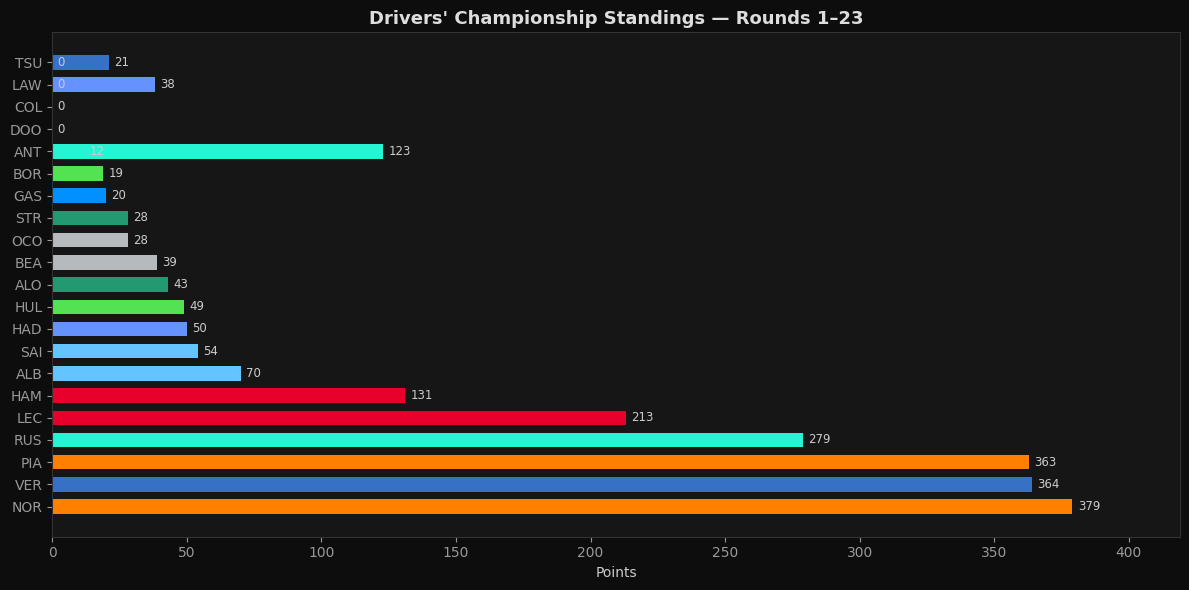

In [4]:
wdc = (
    df.groupby(['Abbreviation', 'FullName', 'TeamName'], as_index=False)['Points']
    .sum().sort_values('Points', ascending=False).reset_index(drop=True)
)
wdc['Color'] = wdc['TeamName'].map(TEAM_COLORS).fillna('#888888')

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(
    wdc['Abbreviation'][::-1], wdc['Points'][::-1],
    color=wdc['Color'][::-1], edgecolor='none', height=0.65
)
for bar, pts in zip(bars, wdc['Points'][::-1]):
    ax.text(pts + 2, bar.get_y() + bar.get_height() / 2,
            f'{pts:.0f}', va='center', fontsize=8.5, color='#cccccc')
ax.set_title("Drivers' Championship Standings — Rounds 1–23")
ax.set_xlabel('Points')
ax.set_xlim(0, wdc['Points'].max() + 40)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 5.2 Constructors' Championship — After Qatar

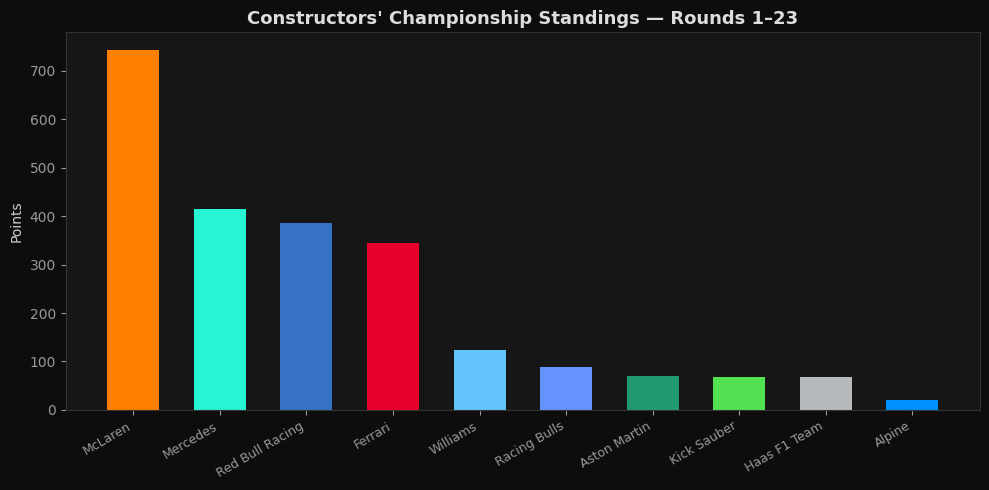

In [5]:
wcc = (
    df.groupby('TeamName', as_index=False)['Points']
    .sum().sort_values('Points', ascending=False)
)
wcc['Color'] = wcc['TeamName'].map(TEAM_COLORS).fillna('#888888')

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(wcc['TeamName'], wcc['Points'], color=wcc['Color'], edgecolor='none', width=0.6)
ax.set_title("Constructors' Championship Standings — Rounds 1–23")
ax.set_ylabel('Points')
ax.set_xticklabels(wcc['TeamName'], rotation=30, ha='right', fontsize=9)
plt.tight_layout()
plt.show()

### 5.3 Championship Battle — Points Progression

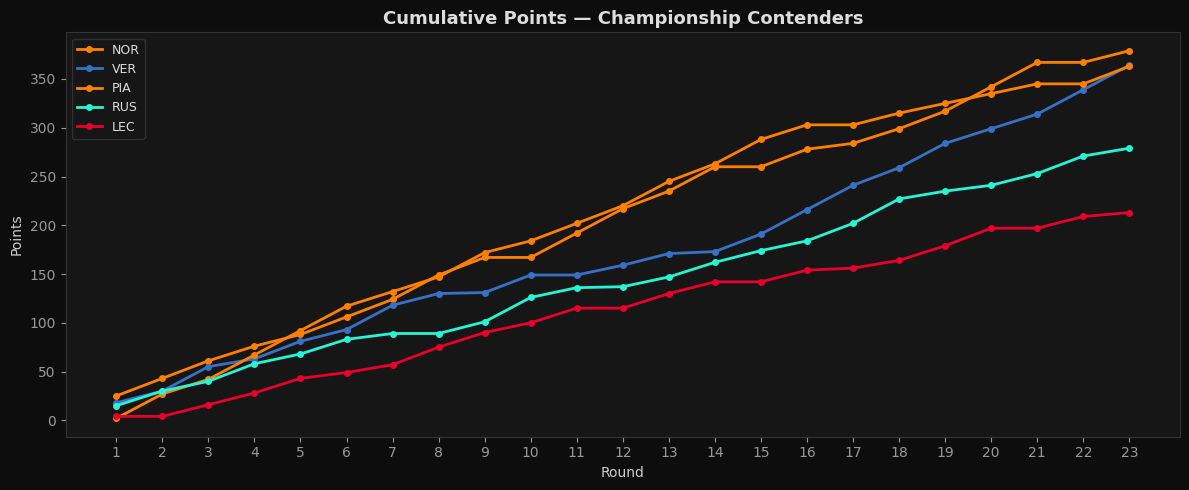

In [6]:
top5 = wdc.head(5)['Abbreviation'].tolist()
df_top5 = df[df['Abbreviation'].isin(top5)].sort_values('Round').copy()
df_top5['CumPoints'] = df_top5.groupby('Abbreviation')['Points'].cumsum()

fig, ax = plt.subplots(figsize=(12, 5))
for drv in top5:
    d = df_top5[df_top5['Abbreviation'] == drv]
    team  = d['TeamName'].iloc[0]
    color = TEAM_COLORS.get(team, '#888888')
    ax.plot(d['Round'], d['CumPoints'], marker='o', markersize=4,
            color=color, label=drv, linewidth=2)
ax.set_title('Cumulative Points — Championship Contenders')
ax.set_xlabel('Round')
ax.set_ylabel('Points')
ax.legend(fontsize=9, framealpha=0.15)
ax.set_xticks(sorted(df['Round'].unique()))
plt.tight_layout()
plt.show()

### 5.4 Grid Position vs Finish Position

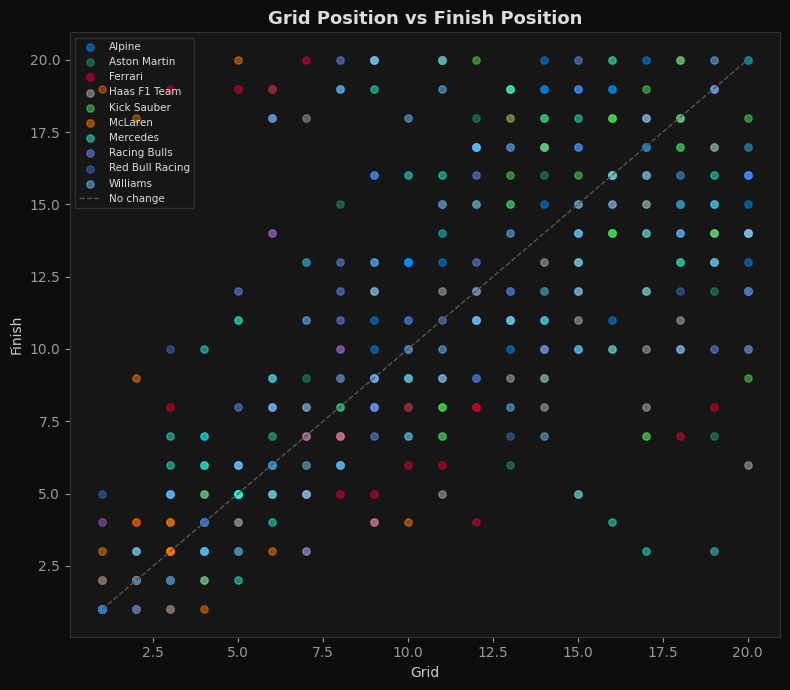

In [7]:
fig, ax = plt.subplots(figsize=(8, 7))
for team, grp in df.groupby('TeamName'):
    color = TEAM_COLORS.get(team, '#888888')
    ax.scatter(grp['GridPosition'], grp['Position'],
               color=color, alpha=0.5, s=28, label=team)
ax.plot([1, 20], [1, 20], '--', color='#555', linewidth=1, label='No change')
ax.set_title('Grid Position vs Finish Position')
ax.set_xlabel('Grid')
ax.set_ylabel('Finish')
ax.legend(fontsize=7.5, loc='upper left', framealpha=0.15)
plt.tight_layout()
plt.show()

### 5.5 Reliability — DNF Rate by Team

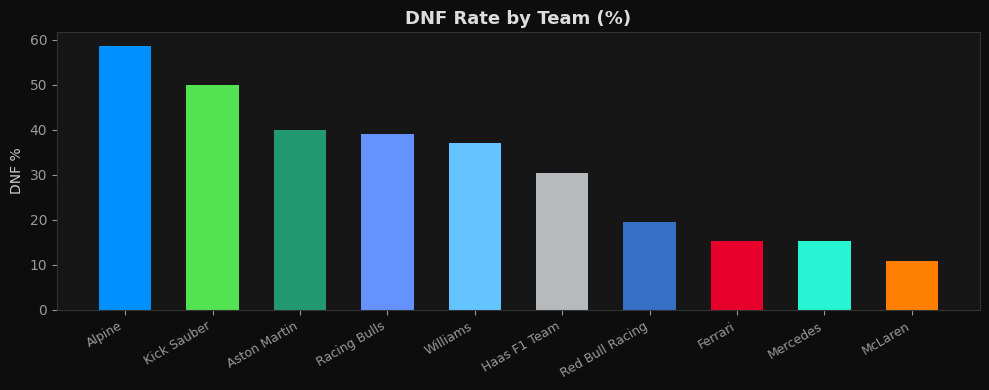

In [8]:
dnf_rate = (
    df.groupby('TeamName')['DNF'].mean()
    .sort_values(ascending=False).reset_index()
)
dnf_rate['Color'] = dnf_rate['TeamName'].map(TEAM_COLORS).fillna('#888888')

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(dnf_rate['TeamName'], dnf_rate['DNF'] * 100,
       color=dnf_rate['Color'], edgecolor='none', width=0.6)
ax.set_title('DNF Rate by Team (%)')
ax.set_ylabel('DNF %')
ax.set_xticklabels(dnf_rate['TeamName'], rotation=30, ha='right', fontsize=9)
plt.tight_layout()
plt.show()

### 5.6 Average Finish Position — Top 10 Drivers

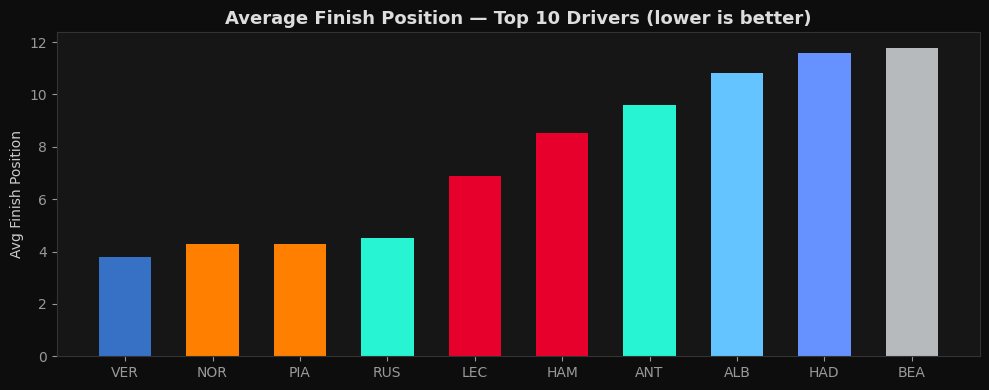

In [9]:
avg_finish = (
    df.groupby(['Abbreviation','TeamName'])['Position']
    .mean().reset_index()
    .sort_values('Position')
    .head(10)
)
avg_finish['Color'] = avg_finish['TeamName'].map(TEAM_COLORS).fillna('#888888')

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(avg_finish['Abbreviation'], avg_finish['Position'],
       color=avg_finish['Color'], edgecolor='none', width=0.6)
ax.set_title('Average Finish Position — Top 10 Drivers (lower is better)')
ax.set_ylabel('Avg Finish Position')
plt.tight_layout()
plt.show()

## 6. Feature Engineering

| Feature | Rationale |
|---------|----------|
| `grid_pos` | Starting grid — strongest single predictor of finish order |
| `driver_avg_pos` | Rolling mean finish position across prior rounds — captures current form |
| `team_avg_pos` | Team's rolling mean — captures car performance level |
| `dnf_rate` | Historical DNF rate — reliability signal |

All features are computed using only past rounds relative to each race, preventing data leakage.


In [10]:
def build_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.sort_values(['Round', 'Position']).reset_index(drop=True)
    rows = []
    for rnd in sorted(df['Round'].unique()):
        past = df[df['Round'] < rnd]
        curr = df[df['Round'] == rnd].copy()
        if past.empty:
            curr['driver_avg_pos'] = 10.0
            curr['team_avg_pos']   = 10.0
            curr['dnf_rate']       = 0.0
        else:
            drv_mean  = past.groupby('Abbreviation')['Position'].mean()
            team_mean = past.groupby('TeamName')['Position'].mean()
            drv_dnf   = past.groupby('Abbreviation')['DNF'].mean()
            curr['driver_avg_pos'] = curr['Abbreviation'].map(drv_mean).fillna(10.0)
            curr['team_avg_pos']   = curr['TeamName'].map(team_mean).fillna(10.0)
            curr['dnf_rate']       = curr['Abbreviation'].map(drv_dnf).fillna(0.0)
        rows.append(curr)
    out = pd.concat(rows, ignore_index=True)
    out = out.rename(columns={'GridPosition': 'grid_pos'})
    return out

FEATURES = ['grid_pos', 'driver_avg_pos', 'team_avg_pos', 'dnf_rate']
df_feat = build_features(df).dropna(subset=FEATURES + ['Position'])
print(f'Feature matrix: {df_feat.shape}')
display(df_feat[FEATURES + ['Position', 'Abbreviation', 'Round']].head(6))

Feature matrix: (459, 15)


,grid_pos,driver_avg_pos,team_avg_pos,dnf_rate,Position,Abbreviation,Round
0,1.0,10.0,10.0,0.0,1.0,NOR,1
1,3.0,10.0,10.0,0.0,2.0,VER,1
2,4.0,10.0,10.0,0.0,3.0,RUS,1
3,16.0,10.0,10.0,0.0,4.0,ANT,1
4,6.0,10.0,10.0,0.0,5.0,ALB,1
5,13.0,10.0,10.0,0.0,6.0,STR,1


## 7. Model Training & Evaluation

**Temporal split:** Rounds 1–17 for training, Rounds 18–23 for evaluation. This ensures the model is never trained on races it is being tested against.

**Primary metric - MAE:** Average absolute error in predicted finish position (in places).  
**Secondary metric - Top-3 precision:** Fraction of actual podium finishers correctly predicted in the top 3.


Train: Rounds 1–17 | Test: Rounds 18–23


,Model,MAE (positions),Top-3 Precision
0,Random Forest,3.231,0.667
1,XGBoost,3.382,0.611


Selected: Random Forest


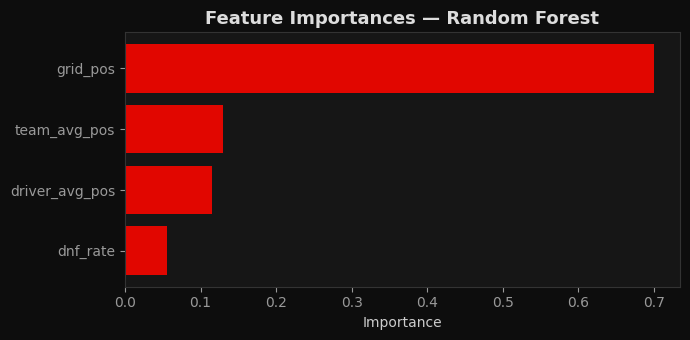

In [11]:
rounds_sorted = sorted(df_feat['Round'].unique())
split_at      = rounds_sorted[int(len(rounds_sorted) * 0.75)]
print(f'Train: Rounds 1–{split_at-1} | Test: Rounds {split_at}–{rounds_sorted[-1]}')

train = df_feat[df_feat['Round'] <  split_at]
test  = df_feat[df_feat['Round'] >= split_at]
X_train, y_train = train[FEATURES], train['Position']
X_test,  y_test  = test[FEATURES],  test['Position']

rf = RandomForestRegressor(n_estimators=300, max_depth=6, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)

xgb_model = xgb.XGBRegressor(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    random_state=RANDOM_STATE, verbosity=0
)
xgb_model.fit(X_train, y_train)

def top3_precision(true_pos, pred_pos):
    df_ev = pd.DataFrame({'true': true_pos.values, 'pred': pred_pos})
    return len(set(df_ev.nsmallest(3,'true').index) & set(df_ev.nsmallest(3,'pred').index)) / 3

rows = []
for name, model in [('Random Forest', rf), ('XGBoost', xgb_model)]:
    preds  = model.predict(X_test)
    mae    = mean_absolute_error(y_test, preds)
    p3     = np.mean([top3_precision(g['Position'], model.predict(g[FEATURES]))
                      for _, g in test.groupby('Round')])
    rows.append({'Model': name, 'MAE (positions)': round(mae, 3), 'Top-3 Precision': round(p3, 3)})

eval_df = pd.DataFrame(rows)
display(eval_df)

best_name  = eval_df.loc[eval_df['MAE (positions)'].idxmin(), 'Model']
best_model = rf if best_name == 'Random Forest' else xgb_model
print(f'Selected: {best_name}')

# Feature importances
imp_df = pd.DataFrame({'Feature': FEATURES, 'Importance': best_model.feature_importances_}).sort_values('Importance')
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(imp_df['Feature'], imp_df['Importance'], color='#e10600', edgecolor='none')
ax.set_title(f'Feature Importances — {best_name}')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

## 8. Championship Prediction

After 23 rounds, one race remains: **Abu Dhabi Grand Prix**.

We use the trained model to estimate each driver's expected finishing position at Abu Dhabi, then propagate the current points standings to determine the probable champion.

Because a single race has inherent variability (tyre failures, incidents, safety cars), we run **10 000 simulations** of the Abu Dhabi race, each perturbed with Gaussian noise around the model's base prediction. The championship probability for each driver is the fraction of simulations in which they end with the highest total points.


In [12]:
F1_POINTS = {1:25, 2:18, 3:15, 4:12, 5:10, 6:8, 7:6, 8:4, 9:2, 10:1}

# Current standings after Qatar
print('Standings after Round 23 — Qatar GP')
print('=' * 40)
display(
    wdc[['Abbreviation', 'FullName', 'TeamName', 'Points']]
    .rename(columns={'Abbreviation': 'Driver', 'FullName': 'Name'})
    .head(10)
    .style.bar(subset=['Points'], color='#3671C6', vmin=0)
    .format({'Points': '{:.0f}'})
)

Standings after Round 23 — Qatar GP


,Driver,Name,TeamName,Points
0,NOR,Lando Norris,McLaren,379
1,VER,Max Verstappen,Red Bull Racing,364
2,PIA,Oscar Piastri,McLaren,363
3,RUS,George Russell,Mercedes,279
4,LEC,Charles Leclerc,Ferrari,213
5,HAM,Lewis Hamilton,Ferrari,131
6,ANT,Kimi Antonelli,Mercedes,123
7,ALB,Alexander Albon,Williams,70
8,SAI,Carlos Sainz,Williams,54
9,HAD,Isack Hadjar,Racing Bulls,50


In [13]:
# Build Abu Dhabi driver feature profile from Round 23 form
last_feats = (
    df_feat[df_feat['Round'] == LAST_ROUND]
    .groupby('Abbreviation', as_index=False)[FEATURES + ['TeamName']].first()
)
drivers       = last_feats['Abbreviation'].tolist()
base_scores   = best_model.predict(last_feats[FEATURES])
pts_lookup    = wdc.set_index('Abbreviation')['Points'].to_dict()
current_pts   = np.array([pts_lookup.get(d, 0) for d in drivers], dtype=float)

rng           = np.random.default_rng(RANDOM_STATE)
n_sim         = 10_000
n_drv         = len(drivers)
champ_counts  = np.zeros(n_drv, dtype=int)

for _ in range(n_sim):
    noise    = rng.normal(0, 2.5, n_drv)
    scores   = base_scores + noise
    pos      = np.argsort(np.argsort(scores)) + 1      # 1-indexed positions
    race_pts = np.array([F1_POINTS.get(int(p), 0) for p in pos], dtype=float)
    champ_counts[np.argmax(current_pts + race_pts)] += 1

sim_df = pd.DataFrame({
    'Driver':     drivers,
    'Team':       last_feats['TeamName'].tolist(),
    'Points':     [pts_lookup.get(d, 0) for d in drivers],
    'Win Prob %': np.round(champ_counts / n_sim * 100, 2),
}).sort_values('Win Prob %', ascending=False).reset_index(drop=True)

display(
    sim_df
    .style.bar(subset=['Win Prob %'], color='#e10600', vmin=0)
    .bar(subset=['Points'], color='#3671C6', vmin=0)
    .format({'Points': '{:.0f}', 'Win Prob %': '{:.1f}%'})
)

,Driver,Team,Points,Win Prob %
0,NOR,McLaren,379,97.5%
1,PIA,McLaren,363,1.9%
2,VER,Red Bull Racing,364,0.6%
3,ALB,Williams,70,0.0%
4,BEA,Haas F1 Team,39,0.0%
5,ANT,Mercedes,12,0.0%
6,ALO,Aston Martin,43,0.0%
7,BOR,Kick Sauber,19,0.0%
8,HAM,Ferrari,131,0.0%
9,COL,Alpine,0,0.0%


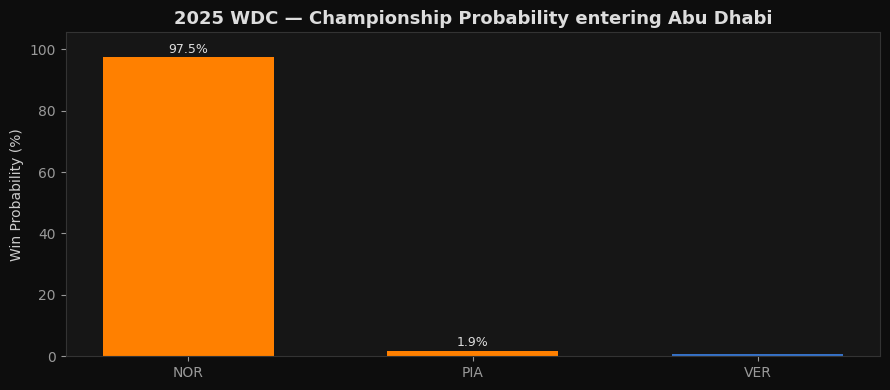

In [14]:
# Visualise — championship probability for drivers with >0% chance
contenders = sim_df[sim_df['Win Prob %'] > 0].copy()
contenders['Color'] = contenders['Team'].map(TEAM_COLORS).fillna('#888888')

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(
    contenders['Driver'], contenders['Win Prob %'],
    color=contenders['Color'], edgecolor='none', width=0.6
)
for bar, prob in zip(bars, contenders['Win Prob %']):
    if prob > 1:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
                f'{prob:.1f}%', ha='center', va='bottom', fontsize=9)
ax.set_title('2025 WDC — Championship Probability entering Abu Dhabi')
ax.set_ylabel('Win Probability (%)')
ax.set_ylim(0, contenders['Win Prob %'].max() + 8)
plt.tight_layout()
plt.show()

In [ ]:
# Gap to leader -> how many points each driver needs to overhaul
leader_pts = sim_df.iloc[0]['Points']
sim_df['Gap to Leader'] = sim_df['Points'].apply(lambda p: 0 if p == leader_pts else leader_pts - p)

fig = go.Figure(go.Bar(
    x=sim_df['Driver'],
    y=sim_df['Gap to Leader'],
    marker_color=[sim_df['Team'].map(TEAM_COLORS).fillna('#888').iloc[i] for i in range(len(sim_df))],
    text=sim_df['Gap to Leader'].apply(lambda g: f'-{g:.0f}' if g > 0 else 'Leader'),
    textposition='outside',
))
fig.update_layout(
    title='Points Gap to Leader -> Entering Abu Dhabi',
    yaxis_title='Points Behind Leader',
    paper_bgcolor='#0d0d0d',
    plot_bgcolor='#161616',
    font_color='#cccccc',
    xaxis_tickangle=-30,
    showlegend=False,
)
fig.show()

## 9. Conclusions

The model was trained on 23 rounds of the 2025 F1 season and evaluated on a temporal holdout set. Feature importance analysis consistently ranked **grid position** as the strongest predictor, followed by rolling driver form.

The championship simulation quantifies the inherent uncertainty of a single race: even a driver with a substantial points lead is not guaranteed the title; a DNF while rivals score big can close any gap.

**Methodological notes:**
- Temporal split prevents any form of data leakage from future races.
- Regression on finish position (not binary win/loss classification) avoids class imbalance issues.
- DNF probability is captured through the `dnf_rate` feature but is applied uniformly via noise; team-specific mechanical failure patterns could be modelled more precisely with more data.
